# EDA: 2011 U.S. Debt Ceiling Standoff, S&P Downgrade and Euro-Area Debt Stress

**Owner:** Salah · **Week 1** · Market Stress Early-Warning System

**Goal:** understand what U.S. equity market stress looked like in 2011 at the stock level, check data quality and survivorship for this period, and test whether co-movement among S&P 500 stocks rose *before* the worst of the stress or only during it (Section 7).

**Before running:** run `python scripts/download_sp500_prices.py` from the repo root. This notebook reads `data/processed/`. If `data/processed/daily_panel.parquet` from `01_data_collection.ipynb` exists, VIX (`VIXCLS`) and the St. Louis Fed Financial Stress Index (`STLFSI4`) are added to the plots and the timing table.

**Window:** 2011-01-01 to 2011-12-31, with 2010 loaded as warm-up for rolling windows.

**Framing.** Two shocks overlapped in summer 2011: the U.S. debt ceiling standoff and S&P downgrade, and the euro-area sovereign debt crisis (our lit review lists 2011 under the euro debt crisis). U.S. stock data alone cannot separate them, so the chart markers include both, drawn in different styles. The stress label (`docs/stress_label_rule.md`) treats 2011-07-25 to 2011-12-08 as one episode covering both shocks, so both sets of markers stay.

**Reference dates** (each checked against the source listed):

| Date | Event | Timing note | Source |
|---|---|---|---|
| 2011-07-21 | Euro-area summit agrees new Greek support package (EU) | During trading | [ECB statement, 7 Aug 2011](https://www.ecb.europa.eu/press/pr/date/2011/html/pr110807.en.html) refers to the summit of 21 July |
| 2011-07-22 | Speaker Boehner walks out of debt talks with President Obama (US) | Friday evening, after the U.S. close; first trading reaction Mon 2011-07-25 | [NPR, 22 Jul 2011](https://www.npr.org/sections/thetwo-way/2011/07/22/138623910/obama-says-boehner-has-broken-off-negotiations) |
| 2011-08-02 | Budget Control Act signed; debt ceiling raised (US) | During trading day | [White House press secretary, 2 Aug 2011](https://obamawhitehouse.archives.gov/realitycheck/node/63739) |
| 2011-08-05 | S&P lowers U.S. long-term rating from AAA to AA+ (US) | Friday, after the U.S. close; first trading reaction Mon 2011-08-08 | [PBS NewsHour, 5 Aug 2011](https://www.pbs.org/newshour/economy/sp-downgrades-us-credit-rating-from-aaa-for-first-time), citing S&P's release |
| 2011-08-07 | ECB says it will actively implement its Securities Markets Programme (Italy/Spain bond purchases) (EU) | Sunday; first trading reaction Mon 2011-08-08 | [ECB press release, 7 Aug 2011](https://www.ecb.europa.eu/press/pr/date/2011/html/pr110807.en.html) |

The earlier draft marked 2011-07-22 as the "debt ceiling standoff peak" without a source. It is now labelled as what happened that day. Because the downgrade came after the close on Friday 2011-08-05, **no market move on 2011-08-05 can be a reaction to it**; the 2011-08-08 marker is the first trading day after both the downgrade and the ECB statement.

In [1]:
%matplotlib inline
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from src import prices as px

PROC = ROOT / "data" / "processed"
WARMUP, START, END = "2010-01-01", "2011-01-01", "2011-12-31"

EVENTS_US = {
    "2011-07-22": "Debt talks collapse (after close)",
    "2011-08-02": "Debt deal signed",
    "2011-08-05": "S&P downgrade (after close)",
    "2011-08-08": "First trading day after downgrade",
}
EVENTS_EU = {
    "2011-07-21": "Euro summit (Greece)",
    "2011-08-07": "ECB bond buying (Sunday)",
}

def mark_events(ax, labels=True):
    for events, color, ls in [(EVENTS_US, "grey", "--"), (EVENTS_EU, "tab:blue", ":")]:
        for d, lab in events.items():
            ax.axvline(pd.Timestamp(d), color=color, ls=ls, lw=0.8)
            if labels:
                ax.text(pd.Timestamp(d), 1.0, f" {lab}", transform=ax.get_xaxis_transform(),
                        rotation=90, va="top", ha="left", fontsize=7, color=color)

pd.set_option("display.width", 140)

## 1. Load data

In [2]:
close = pd.read_parquet(PROC / "sp500_close.parquet").loc[WARMUP:END]
membership = pd.read_parquet(PROC / "sp500_membership.parquet").loc[WARMUP:END]
report = pd.read_csv(PROC / "sp500_coverage_report.csv", index_col="ticker",
                     parse_dates=["first_price", "last_price", "first_member_day"])

# Daily simple returns from unmasked prices, then keep member days only.
stock_cols = membership.columns
rets_all = close.reindex(columns=stock_cols).pct_change(fill_method=None)
rets = rets_all.where(membership)

gspc = close["^GSPC"]
print(f"{close.index.min().date()} to {close.index.max().date()}: {len(close)} trading days")
print(f"{len(stock_cols)} tickers were members at some point in the full download period")

2010-01-04 to 2011-12-30: 504 trading days
977 tickers were members at some point in the full download period


## 2. Data quality: how much of the index do we actually see?

Survivorship check: on each day, what share of the stocks that were *in the index that day* have a Yahoo price?

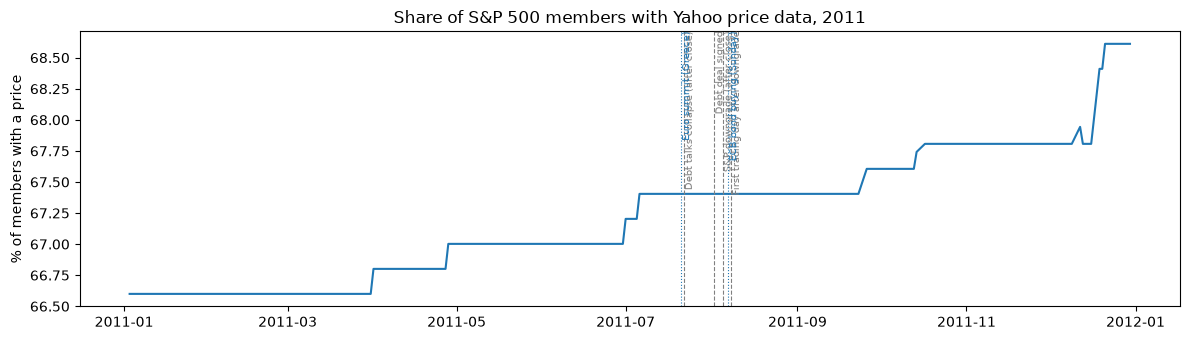

Average share priced, full window:      67.2%
Average share priced, Jul-Oct 2011:     67.5%
Lowest daily share: 66.6% on 2011-01-03


In [3]:
cov = px.coverage_by_day(close, membership).loc[START:END]

fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(cov.index, cov["share_priced"] * 100)
ax.set_ylabel("% of members with a price")
ax.set_title("Share of S&P 500 members with Yahoo price data, 2011")
mark_events(ax)
plt.tight_layout(); plt.show()

stress = cov.loc["2011-07-01":"2011-10-31"]
print(f"Average share priced, full window:      {cov['share_priced'].mean():.1%}")
print(f"Average share priced, Jul-Oct 2011:     {stress['share_priced'].mean():.1%}")
print(f"Lowest daily share: {cov['share_priced'].min():.1%} on {cov['share_priced'].idxmin().date()}")

In [4]:
# Members during the window with no or partial price data, ranked by days in the index during the window
win_mem = membership.loc[START:END]
win_has = close.reindex(columns=stock_cols).loc[START:END].notna() & win_mem
gap = pd.DataFrame({
    "member_days_in_window": win_mem.sum(),
    "priced_days_in_window": win_has.sum(),
})
gap = gap[gap["member_days_in_window"] > 0]
gap["coverage_in_window"] = (gap["priced_days_in_window"] / gap["member_days_in_window"]).round(3)
missing = gap[gap["coverage_in_window"] < 1].sort_values(["member_days_in_window", "coverage_in_window"],
                                                         ascending=[False, True])
missing = missing.join(report[["first_price", "last_price", "late_start", "check_ticker_reuse"]], how="left")
print(f"{len(missing)} of {len(gap)} window members have incomplete prices; "
      f"{int((gap['priced_days_in_window'] == 0).sum())} have none")
missing.head(40)

172 of 515 window members have incomplete prices; 172 have none


,member_days_in_window,priced_days_in_window,coverage_in_window,first_price,last_price,late_start,check_ticker_reuse
AABA,252,0,0.0,NaT,NaT,False,False
AET,252,0,0.0,NaT,NaT,False,False
AGN,252,0,0.0,NaT,NaT,False,False
ALTR,252,0,0.0,NaT,NaT,False,False
ANDV,252,0,0.0,NaT,NaT,False,False
APC,252,0,0.0,2026-02-12,2026-10-28,False,False
APOL,252,0,0.0,NaT,NaT,False,False
ARG,252,0,0.0,NaT,NaT,False,False
ARNC,252,0,0.0,NaT,NaT,False,False
ATGE,252,0,0.0,NaT,NaT,False,False


*Note for the write-up:* unlike 2008, most of the 2011 gaps are not firms that failed in the crisis. Many are **renamed tickers** that the membership file stores under the old symbol while Yahoo only has the new one (for example `BK` is now `BNY`, `ABC` is now `COR`, `ANTM` is now `ELV`, `BLL` is now `BALL`; the new symbols are already in `data/raw/prices/`). The rest are mostly firms acquired after 2011. So the 2011 coverage gap is largely a ticker-mapping problem, and it is less likely to bias 2011 stress measures in one direction than the 2008 gap. **Update:** these four are now mapped in `TICKER_ALIASES` (`src/universe.py`) and recorded in `docs/survivorship_bias.md`; rerun the download script and this notebook to see the higher coverage.

### 2b. Price sanity: implausible daily returns

A few tickers have prices that cannot belong to the 2011 company (for example a 376% one-day gain). These are most likely ticker reuse that the coverage report's `check_ticker_reuse` flag did not catch. A single bad price can dominate cross-sectional dispersion, so member-days with an absolute daily return above 40% are listed here and those tickers are excluded from the stock-level measures below.

In [5]:
JUMP = 0.40
r_win = rets.loc[START:END]
jumps = r_win.stack()
jumps = jumps[jumps.abs() > JUMP].rename("daily_return").reset_index()
jumps.columns = ["date", "ticker", "daily_return"]
print(jumps.sort_values(["ticker", "date"]).to_string(index=False))

BAD_TICKERS = sorted(jumps["ticker"].unique())
print(f"\nExcluded from stock-level measures: {BAD_TICKERS}")
rets = rets.drop(columns=BAD_TICKERS)
stock_cols = stock_cols.drop(BAD_TICKERS)

      date ticker  daily_return
2011-01-13   CPWR      1.000000
2011-02-16   CPWR     -0.475000
2011-05-23   CPWR     -0.900000
2011-06-03   CPWR      3.761912
2011-06-27   CPWR     -0.500000
2011-08-16   CPWR      3.000002
2011-09-07   CPWR     -0.750000
2011-10-03   CPWR     -0.400000
2011-12-23   CPWR      1.000000
2011-01-06     EP      0.833333
2011-01-28     EP      0.400000
2011-10-18     EP      0.600000

Excluded from stock-level measures: ['CPWR', 'EP']


## 3. Market overview: level, drawdown and volatility

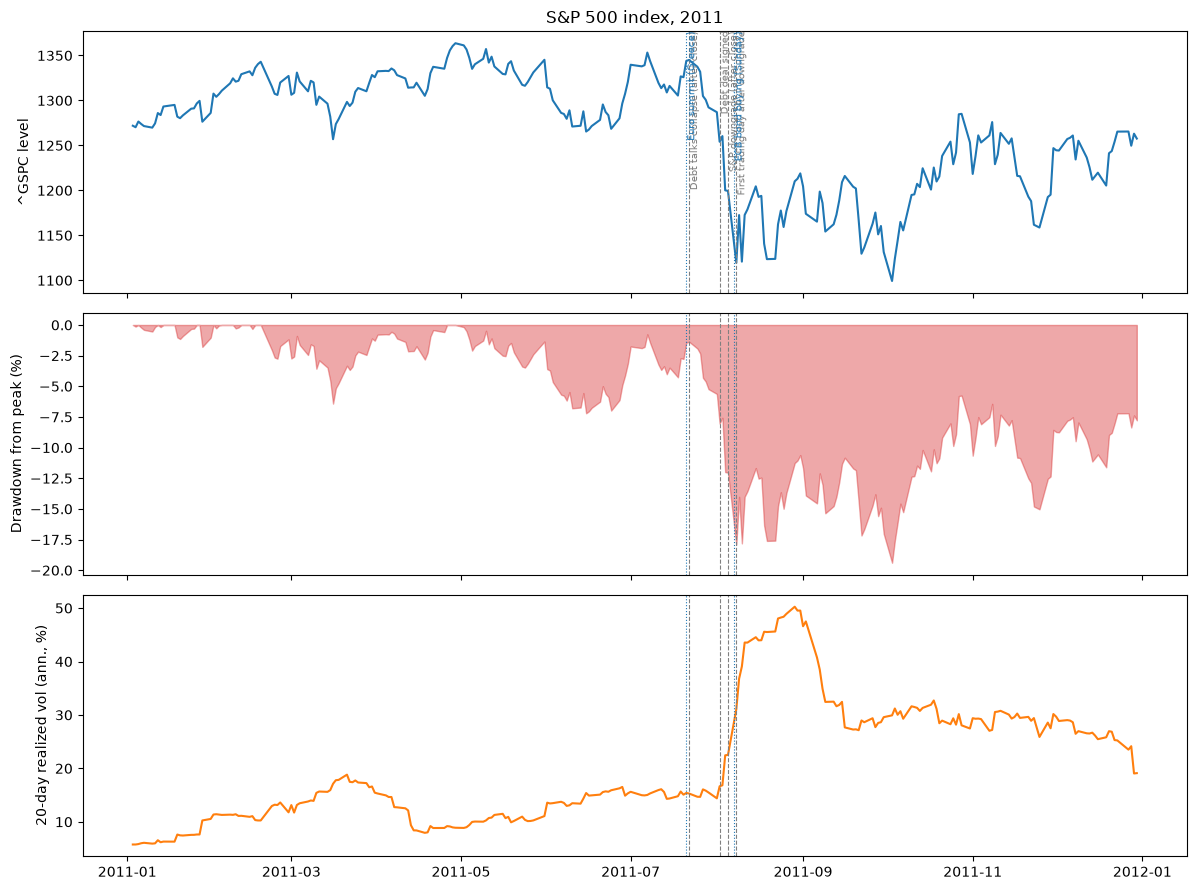

Peak close before the drawdown: 1,363.61 on 2011-04-29
Trough close: 1,099.23 on 2011-10-03
Maximum drawdown: -19.4%
Highest 20-day realized vol: 50.3% on 2011-08-29
Average 20-day realized vol, Jan-Jun 2011: 11.8%

^GSPC daily returns around the downgrade:
Date
2011-08-01   -0.41
2011-08-02   -2.56
2011-08-03    0.50
2011-08-04   -4.78
2011-08-05   -0.06
2011-08-08   -6.66
2011-08-09    4.74
2011-08-10   -4.42
2011-08-11    4.63
2011-08-12    0.53


In [6]:
g = gspc.loc[START:END]
drawdown = g / g.cummax() - 1
vol20 = gspc.pct_change(fill_method=None).rolling(20).std().loc[START:END] * np.sqrt(252)

fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
axes[0].plot(g.index, g); axes[0].set_ylabel("^GSPC level")
axes[1].fill_between(drawdown.index, drawdown * 100, 0, color="tab:red", alpha=0.4)
axes[1].set_ylabel("Drawdown from peak (%)")
axes[2].plot(vol20.index, vol20 * 100, color="tab:orange"); axes[2].set_ylabel("20-day realized vol (ann., %)")
for i, ax in enumerate(axes):
    mark_events(ax, labels=(i == 0))
axes[0].set_title("S&P 500 index, 2011")
plt.tight_layout(); plt.show()

trough_date = drawdown.idxmin()
peak_date = g.loc[:trough_date].idxmax()
print(f"Peak close before the drawdown: {g[peak_date]:,.2f} on {peak_date.date()}")
print(f"Trough close: {g[trough_date]:,.2f} on {trough_date.date()}")
print(f"Maximum drawdown: {drawdown.min():.1%}")
print(f"Highest 20-day realized vol: {vol20.max():.1%} on {vol20.idxmax().date()}")
print(f"Average 20-day realized vol, Jan-Jun 2011: {vol20.loc[:'2011-06-30'].mean():.1%}")
print("\n^GSPC daily returns around the downgrade:")
print((gspc.pct_change(fill_method=None).loc["2011-08-01":"2011-08-12"] * 100).round(2).to_string())

### 3b. VIX and the St. Louis Fed Financial Stress Index (optional)

Runs only if `daily_panel.parquet` from `01_data_collection.ipynb` exists. Both series are FRED data. `STLFSI4` is weekly and is forward-filled onto trading days by observation date, which is fine for EDA but **not** for modeling (release lag, see `01_data_collection.ipynb`).

VIX peak close: 48.0 on 2011-08-08
STLFSI4 peak: 1.40 on 2011-10-07


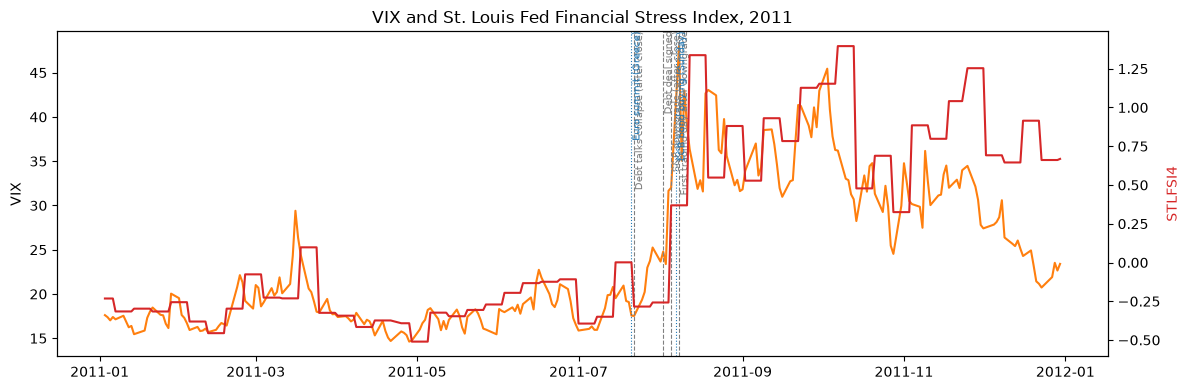

In [7]:
panel_path = PROC / "daily_panel.parquet"
vix = stl = None
if panel_path.exists():
    panel = pd.read_parquet(panel_path)
    if "VIXCLS" in panel:
        vix = panel["VIXCLS"].reindex(close.index).ffill()
    if "STLFSI4" in panel:
        stl = panel["STLFSI4"].ffill().reindex(close.index, method="ffill")

if vix is None and stl is None:
    print("daily_panel.parquet not found; run 01_data_collection.ipynb to add VIX and STLFSI4.")
else:
    fig, ax1 = plt.subplots(figsize=(12, 4))
    if vix is not None:
        v = vix.loc[START:END]
        ax1.plot(v.index, v, color="tab:orange", label="VIX close"); ax1.set_ylabel("VIX")
        print(f"VIX peak close: {v.max():.1f} on {v.idxmax().date()}")
    if stl is not None:
        ax2 = ax1.twinx()
        s = stl.loc[START:END]
        ax2.plot(s.index, s, color="tab:red", label="STLFSI4"); ax2.set_ylabel("STLFSI4", color="tab:red")
        print(f"STLFSI4 peak: {s.max():.2f} on {s.idxmax().date()}")
    mark_events(ax1)
    ax1.set_title("VIX and St. Louis Fed Financial Stress Index, 2011")
    plt.tight_layout(); plt.show()

## 4. Sanity check: equal-weighted member portfolio vs the index

The official index is cap-weighted, so the two lines should move together but not match. A large, persistent gap would point to a data problem.

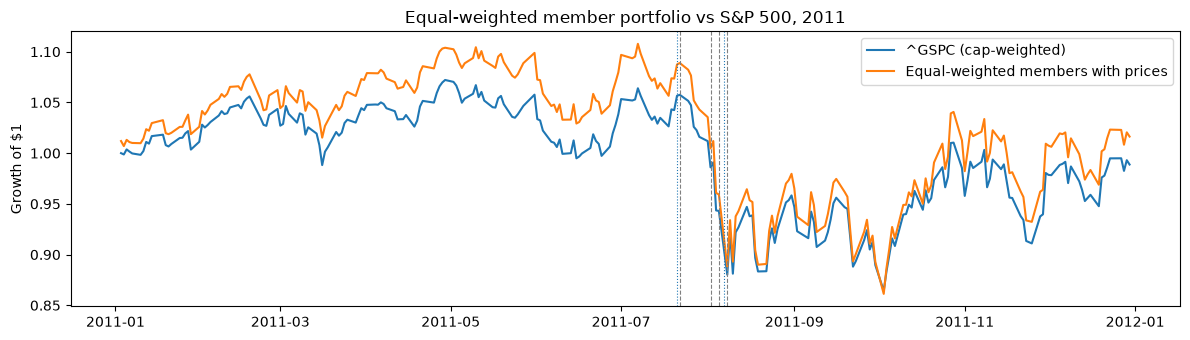

Correlation of daily returns (EW vs ^GSPC): 0.995
2011 total return: EW 1.6%, ^GSPC price index -1.1%


In [8]:
ew = rets.loc[START:END].mean(axis=1, skipna=True)
ew_level = (1 + ew.fillna(0)).cumprod()
ix_level = g / g.iloc[0]

fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(ix_level.index, ix_level, label="^GSPC (cap-weighted)")
ax.plot(ew_level.index, ew_level, label="Equal-weighted members with prices")
ax.set_ylabel("Growth of $1"); ax.legend(); mark_events(ax, labels=False)
ax.set_title("Equal-weighted member portfolio vs S&P 500, 2011")
plt.tight_layout(); plt.show()

daily_corr = ew.corr(gspc.pct_change(fill_method=None).loc[START:END])
print(f"Correlation of daily returns (EW vs ^GSPC): {daily_corr:.3f}")
print(f"2011 total return: EW {ew_level.iloc[-1] - 1:.1%}, ^GSPC price index {ix_level.iloc[-1] - 1:.1%}")

*Note:* `^GSPC` is a price index, while the member returns come from dividend-adjusted closes, so the equal-weighted line should end slightly higher even with identical stocks.

## 5. Cross-section: dispersion and breadth

* **Dispersion:** standard deviation of returns across stocks each day.
* **Breadth:** share of members trading above their own 50-day moving average.

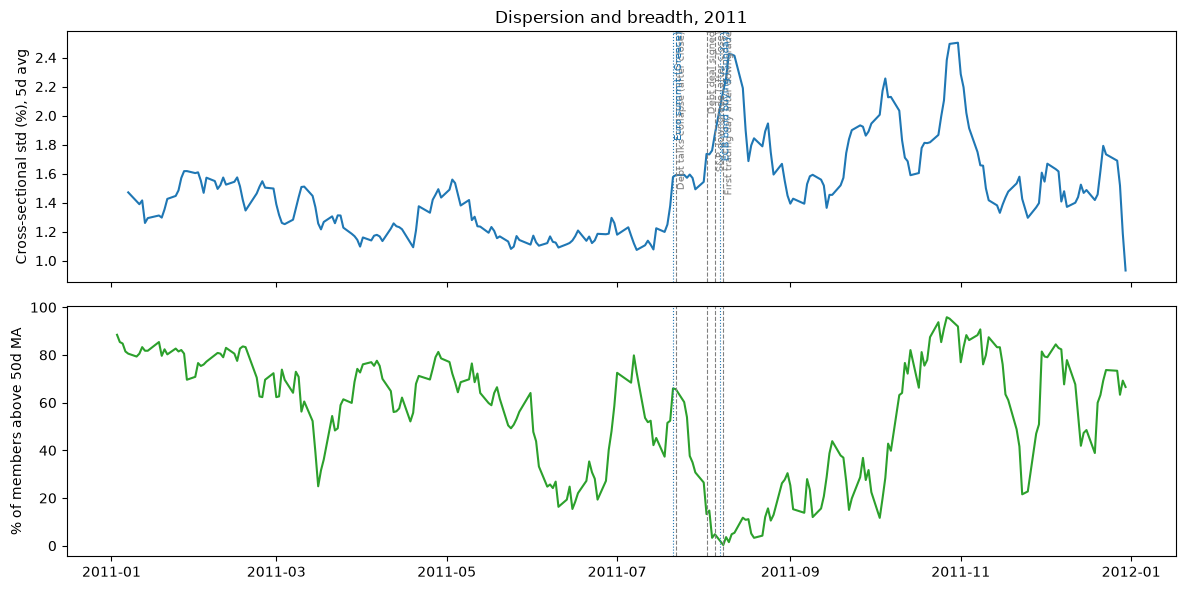

Dispersion (5d avg): Jan-Jun mean 1.31%, peak 2.50% on 2011-10-31
Breadth: Jan-Jun mean 62.2%, low 0.3% on 2011-08-08


In [9]:
dispersion = rets.loc[START:END].std(axis=1, skipna=True)
ma50 = close.reindex(columns=stock_cols).rolling(50, min_periods=50).mean()
above = (close.reindex(columns=stock_cols) > ma50).where(membership[stock_cols] & ma50.notna())
breadth = above.mean(axis=1, skipna=True).loc[START:END]
disp5 = dispersion.rolling(5).mean()

fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
axes[0].plot(disp5.index, disp5 * 100)
axes[0].set_ylabel("Cross-sectional std (%), 5d avg")
axes[1].plot(breadth.index, breadth * 100, color="tab:green")
axes[1].set_ylabel("% of members above 50d MA")
for i, ax in enumerate(axes):
    mark_events(ax, labels=(i == 0))
axes[0].set_title("Dispersion and breadth, 2011")
plt.tight_layout(); plt.show()

print(f"Dispersion (5d avg): Jan-Jun mean {disp5.loc[:'2011-06-30'].mean():.2%}, "
      f"peak {disp5.max():.2%} on {disp5.idxmax().date()}")
print(f"Breadth: Jan-Jun mean {breadth.loc[:'2011-06-30'].mean():.1%}, "
      f"low {breadth.min():.1%} on {breadth.idxmin().date()}")

## 6. Connectedness: did stocks start moving together before the worst of the stress?

For every 5th trading day, take the previous 60 trading days of returns for stocks that were members with complete data over that window, and compute the **average pairwise correlation** and the **first principal component variance share** (largest eigenvalue / number of stocks). Both measure co-movement *among S&P 500 stocks*, not across asset classes.

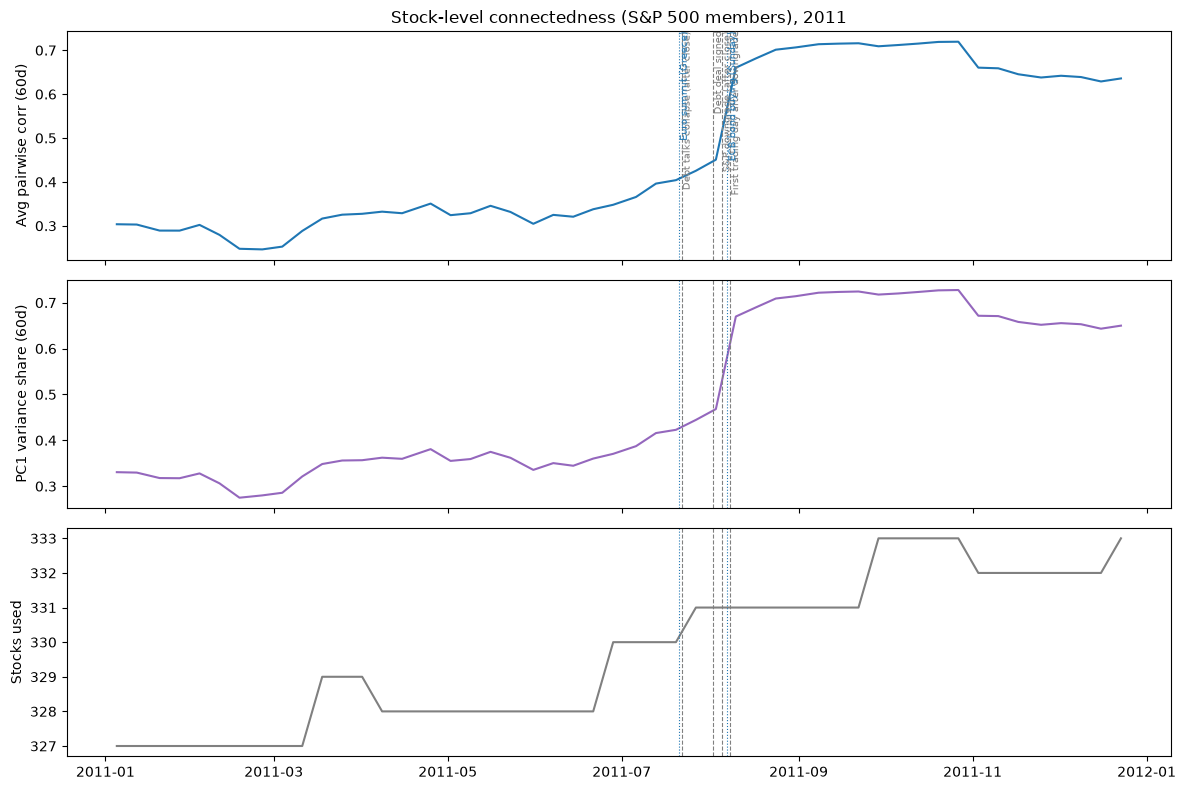

In [10]:
def connectedness(returns: pd.DataFrame, window: int = 60, step: int = 5, min_stocks: int = 100) -> pd.DataFrame:
    rows = {}
    idx = returns.index
    for end in range(window, len(idx) + 1, step):
        block = returns.iloc[end - window:end]
        block = block.loc[:, block.notna().all()]          # complete data over the window only
        block = block.loc[:, block.std() > 0]
        n = block.shape[1]
        if n < min_stocks:
            continue
        c = np.corrcoef(block.values, rowvar=False)
        avg = (c.sum() - n) / (n * (n - 1))
        top = np.linalg.eigvalsh(c)[-1] / n
        rows[idx[end - 1]] = {"avg_corr": avg, "pc1_share": top, "n_stocks": n}
    return pd.DataFrame(rows).T.astype(float)

conn_full = connectedness(rets.loc[WARMUP:END])
conn = conn_full.loc[START:END]

fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
axes[0].plot(conn.index, conn["avg_corr"]); axes[0].set_ylabel("Avg pairwise corr (60d)")
axes[1].plot(conn.index, conn["pc1_share"], color="tab:purple"); axes[1].set_ylabel("PC1 variance share (60d)")
axes[2].plot(conn.index, conn["n_stocks"], color="grey"); axes[2].set_ylabel("Stocks used")
for i, ax in enumerate(axes):
    mark_events(ax, labels=(i == 0))
axes[0].set_title("Stock-level connectedness (S&P 500 members), 2011")
plt.tight_layout(); plt.show()

Average correlation before, during and after August. Each value is a trailing 60-day window ending on the listed date, so a window ending in early August still mostly covers June and July.

In [11]:
periods = {
    "Jan-Jun 2011 (before)": ("2011-01-01", "2011-06-30"),
    "Jul 2011 (standoff)": ("2011-07-01", "2011-07-31"),
    "Aug 2011 (downgrade)": ("2011-08-01", "2011-08-31"),
    "Sep-Oct 2011 (after)": ("2011-09-01", "2011-10-31"),
    "Nov-Dec 2011 (after)": ("2011-11-01", "2011-12-31"),
}
period_stats = pd.DataFrame({
    name: {"mean avg_corr": conn.loc[a:b, "avg_corr"].mean(),
           "min": conn.loc[a:b, "avg_corr"].min(),
           "max": conn.loc[a:b, "avg_corr"].max(),
           "mean PC1 share": conn.loc[a:b, "pc1_share"].mean()}
    for name, (a, b) in periods.items()
}).T.round(3)
display(period_stats)

# When did the summer rise start? Last local low before August, then the first window with a jump.
pre_aug = conn.loc["2011-05-01":"2011-07-31", "avg_corr"]
low_date = pre_aug.idxmin()
print(f"Lowest avg corr Jan-Jun: {conn.loc[:'2011-06-30', 'avg_corr'].min():.3f} on "
      f"{conn.loc[:'2011-06-30', 'avg_corr'].idxmin().date()}")
print(f"Last low before August: {pre_aug.min():.3f} on {low_date.date()}; avg corr rose in "
      f"{int((conn.loc[low_date:'2011-08-03', 'avg_corr'].diff().dropna() > 0).sum())} of "
      f"{len(conn.loc[low_date:'2011-08-03']) - 1} windows from then to 2011-08-03 "
      f"(to {conn.loc[:'2011-08-03', 'avg_corr'].iloc[-1]:.3f})")
jump = conn["avg_corr"].diff()
print(f"Largest single-step jump: +{jump.max():.3f} in the window ending {jump.idxmax().date()}")
print(f"Peak: {conn['avg_corr'].max():.3f} on {conn['avg_corr'].idxmax().date()}")

,mean avg_corr,min,max,mean PC1 share
Jan-Jun 2011 (before),0.310,0.246,0.351,0.339
Jul 2011 (standoff),0.398,0.366,0.425,0.418
Aug 2011 (downgrade),0.640,0.451,0.706,0.650
Sep-Oct 2011 (after),0.715,0.709,0.719,0.723
Nov-Dec 2011 (after),0.644,0.629,0.660,0.657


Lowest avg corr Jan-Jun: 0.246 on 2011-02-25
Last low before August: 0.305 on 2011-05-31; avg corr rose in 8 of 9 windows from then to 2011-08-03 (to 0.451)
Largest single-step jump: +0.210 in the window ending 2011-08-10
Peak: 0.719 on 2011-10-27


## 7. Timing table: when did each measure first get unusual?

For each measure, the first date its value exceeded a baseline mean by 2 standard deviations, plus its peak date. This is a rough timing comparison, not a lead-time test (that comes in Week 6). The 2-standard-deviation rule is an arbitrary EDA choice.

**Two baselines**, because 2010 was not calm: it includes the 2010-05-06 flash crash and the first Greek/euro-area stress, and average correlation was already high in 2010 (see below). A 2010 baseline therefore sets a high bar.

* **A: calendar 2010** (template choice). Search window: all of 2011.
* **B: Jan-Jun 2011**, the calmest stretch available before the standoff. Search window: 2011-07-01 onward, so a measure cannot cross a threshold inside its own baseline.

Connectedness values need 60 trading days of history, so baseline A for correlation and PC1 covers only windows ending from April 2010.

In [12]:
vol20_full = gspc.pct_change(fill_method=None).rolling(20).std() * np.sqrt(252)
disp_full = rets.std(axis=1, skipna=True).rolling(5).mean()

measures = {
    "20d realized vol": vol20_full,
    "dispersion (5d avg)": disp_full,
    "avg pairwise corr": conn_full["avg_corr"],
    "PC1 variance share": conn_full["pc1_share"],
}
if vix is not None:
    measures["VIX"] = vix
if stl is not None:
    measures["STLFSI4"] = stl

BASELINES = {
    "A: 2010": (slice("2010-01-01", "2010-12-31"), slice(START, END)),
    "B: Jan-Jun 2011": (slice("2011-01-01", "2011-06-30"), slice("2011-07-01", END)),
}

rows = []
for bname, (pre, search) in BASELINES.items():
    for name, s in measures.items():
        s = s.astype(float)
        base = s.loc[pre].dropna()
        thr = base.mean() + 2 * base.std()
        w = s.loc[search]
        hit = w[w > thr]
        rows.append({
            "baseline": bname, "measure": name,
            "baseline mean": round(base.mean(), 4),
            "threshold (mean + 2 sd)": round(thr, 4),
            "first date above threshold": hit.index[0].date() if len(hit) else None,
            "peak date (2011)": s.loc[START:END].idxmax().date(),
            "peak value": round(s.loc[START:END].max(), 4),
        })
timing = pd.DataFrame(rows).set_index(["baseline", "measure"])
timing

baseline mean  threshold (mean + 2 sd) first date above threshold peak date (2011)  peak value
baseline        measure                                                                                                            
A: 2010         20d realized vol            0.1729                   0.3088                 2011-08-08       2011-08-29      0.5025
                dispersion (5d avg)         0.0139                   0.0180                 2011-08-05       2011-10-31      0.0250
                avg pairwise corr           0.4918                   0.7072                 2011-09-08       2011-10-27      0.7195
                PC1 variance share          0.5127                   0.7204                 2011-09-08       2011-10-27      0.7275
                VIX                        22.5489                  33.0955                 2011-08-08       2011-08-08     48.0000
                STLFSI4                     0.0807                   0.9068                 2011-08-12       2011-10-07      1.3960
B: Jan-Jun 2011 20d realized vol            0.1180                   0.1845                 2011-08-04       2011-08-29      0.5025
                dispersion (5d avg)         0.0130                   0.0164                 2011-08-02       2011-10-31      0.0250
                avg pairwise corr           0.3099                   0.3699                 2011-07-13       2011-10-27      0.7195
                PC1 variance share          0.3387                   0.3972                 2011-07-13       2011-10-27      0.7275
                VIX                        18.0441                  22.7115                 2011-07-27       2011-08-08     48.0000
                STLFSI4                    -0.2743                  -0.0137                 2011-07-15       2011-10-07      1.3960

## 8. Robustness: does a fixed, survivor-style panel change the connectedness picture?

Section 6 uses a rolling universe. Here we recompute it using only stocks that were members **and** had a price on **every** trading day of 2011. If the two lines differ a lot, the network results are sensitive to how we handle index changes and missing firms.

Fixed panel: 327 stocks present and priced on all 252 trading days of 2011


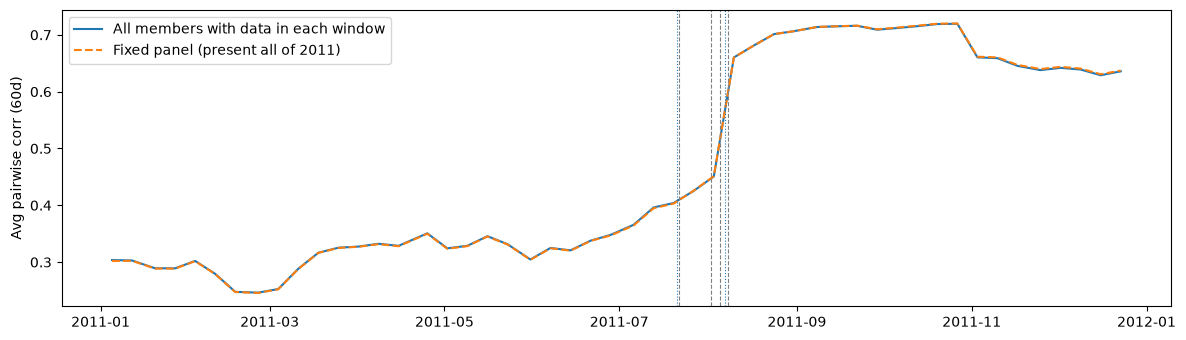

Max absolute difference in avg corr: 0.0019 (window ending 2011-11-25)


/var/folders/x3/1yphdl8177j5_g_gybtgsl8r0000gn/T/ipykernel_2313/1432294096.py:14: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  both = conn[["avg_corr"]].join(conn_fixed[["avg_corr"]], rsuffix="_fixed").dropna()


In [13]:
n_days = len(win_mem)
fixed = gap.index[(gap["member_days_in_window"] == n_days) & (gap["priced_days_in_window"] == n_days)]
fixed = fixed.difference(BAD_TICKERS)
print(f"Fixed panel: {len(fixed)} stocks present and priced on all {n_days} trading days of 2011")

conn_fixed = connectedness(rets.loc[WARMUP:END, fixed]).loc[START:END]

fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(conn.index, conn["avg_corr"], label="All members with data in each window")
ax.plot(conn_fixed.index, conn_fixed["avg_corr"], label="Fixed panel (present all of 2011)", ls="--")
ax.set_ylabel("Avg pairwise corr (60d)"); ax.legend(); mark_events(ax, labels=False)
plt.tight_layout(); plt.show()

both = conn[["avg_corr"]].join(conn_fixed[["avg_corr"]], rsuffix="_fixed").dropna()
diff = (both["avg_corr"] - both["avg_corr_fixed"]).abs()
print(f"Max absolute difference in avg corr: {diff.max():.4f} (window ending {diff.idxmax().date()})")

## 9. Observations

Every point cites the output it comes from. Section numbers refer to this notebook.

1. **Volatility (replaces the VIX claim):** This notebook does not load the VIX unless `daily_panel.parquet` exists (Section 3b), so the point uses realized volatility. The 20-day realized volatility of `^GSPC` rose from an average of 11.8% in January to June to a peak of **50.3% on 2011-08-29** (Section 3). It first crossed its threshold on 2011-08-04 against the Jan-Jun 2011 baseline and on **2011-08-08** against the 2010 baseline (Section 7).
2. **Drawdown:** The S&P 500 fell **19.4%** from its close of 1,363.61 on **2011-04-29** to 1,099.23 on **2011-10-03** (Section 3). The two largest daily losses were -6.66% on 2011-08-08, the first trading day after the downgrade, and -4.78% on 2011-08-04, the day *before* the downgrade. The index moved -0.06% on 2011-08-05, which cannot reflect the downgrade because it was announced after that day's close.
3. **Connectedness (stocks within the S&P 500, not asset classes):** The 60-day average pairwise correlation averaged **0.309** in January to June (low 0.245 on 2011-02-25), **0.397** in July, **0.640** in August, **0.715** in September and October (peak **0.719** on 2011-10-27), and **0.643** in November and December (Section 6). The summer rise began after a low of **0.304 on 2011-05-31**: the measure rose in 8 of the next 9 windows, reaching 0.451 by 2011-08-03. The largest single jump (+0.209) came in the window ending 2011-08-10, which is the first to include the 4 to 10 August selloff. The PC1 variance share follows the same path (0.338, 0.417, 0.650, 0.723, 0.656 by period).
4. **Did co-movement rise before the worst of the stress? It depends on the baseline (Section 7).** Against the calm Jan-Jun 2011 baseline, average correlation and the PC1 share both crossed their thresholds on **2011-07-13**, before the debt talks collapsed (2011-07-22), before volatility crossed (2011-08-04) and seven weeks before the volatility peak. Against the 2010 baseline, both crossed only on **2011-09-08**, a month after volatility. The 2010 baseline is high because 2010 already had elevated co-movement (mean 0.49, against 0.31 in early 2011) from the flash crash and the first euro-area stress. Conclusion: co-movement became unusual relative to a calm period before the acute phase, but did not exceed 2010's already stressed levels until after it.
5. **Persistence:** Correlation peaked on 2011-10-27, two months after the volatility peak. Part of this is mechanical: the August selloff days stay inside the 60-day window until about early November.
6. **Cross-section:** Breadth fell from an average of 62.0% of members above their 50-day average in January to June to **0.3% on 2011-08-08** (Section 5). Dispersion first crossed its threshold on 2011-08-02 (Jan-Jun baseline) and 2011-08-05 (2010 baseline), but it peaked at 2.51% on 2011-10-31, during Q3 earnings season (for example Netflix fell 35% on 2011-10-25), so its peak reflects stock-specific news rather than macro stress.
7. **Data coverage and quality:** On average 66.4% of members had a Yahoo price (66.7% from July to October); 176 of 515 window members have no prices at all (Section 2). Many of these are renamed tickers rather than failed firms, so this is mostly a ticker-mapping gap. Two tickers, CPWR and EP, had impossible prices (one-day moves up to +376%) and are excluded (Section 2b); before the exclusion they produced a false dispersion peak on 2011-06-03.
8. **Sanity check and robustness:** Daily returns of the equal-weighted member portfolio correlate **0.995** with `^GSPC` (Section 4). A fixed panel of the **323** stocks priced on all 252 trading days gives nearly the same average correlation (maximum difference **0.0019**, Section 8).
9. **Implications for the model:** The lead-or-lag answer for 2011 changes with the baseline, so the Week 6 tests need a fixed baseline rule decided in advance (for example, a trailing calm window) rather than a calendar year. The 60-day window delays and prolongs the correlation signal; a shorter window is worth testing. The U.S. and euro-area shocks overlap in time, so the 2011 episode label must match the stress label definition (`docs/stress_label_rule.md`).

## Save outputs for the team

In [14]:
out = PROC / "eda_2011"
out.mkdir(parents=True, exist_ok=True)
conn.to_csv(out / "connectedness_60d.csv")
conn_fixed.to_csv(out / "connectedness_60d_fixed_panel.csv")
cov.to_csv(out / "coverage_by_day.csv")
missing.to_csv(out / "members_missing_prices.csv")
jumps.to_csv(out / "implausible_returns.csv", index=False)
period_stats.to_csv(out / "avg_corr_by_period.csv")
timing.to_csv(out / "timing_table.csv")
print("Saved to", out.relative_to(ROOT))
for f in sorted(out.iterdir()):
    print("  ", f.name)

Saved to data/processed/eda_2011
   avg_corr_by_period.csv
   connectedness_60d.csv
   connectedness_60d_fixed_panel.csv
   coverage_by_day.csv
   implausible_returns.csv
   members_missing_prices.csv
   timing_table.csv
